# Problem 1:  RNN, LSTM and GRU on sequences 
# DNN Assignment_2 
## Name : Nishant Gupta , Student Id : 2026AJ05092
This notebook contains the complete custom RNN, LSTM, and GRU implementation from scratch, evaluation on the Human Activity Recognition (UCI HAR) classification task, and gradient/clipping analysis.

In [1]:
import os
import math
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import urllib.request
import zipfile
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# Create directory structure
project_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'problem1' else os.getcwd()
P1_DIR = os.path.join(project_root, 'problem1')
FIGURE_DIR = os.path.join(P1_DIR, 'figures')
os.makedirs(FIGURE_DIR, exist_ok=True)

# Initialize Results CSV
csv_path = os.path.join(project_root, 'results.csv')
results_cols = [
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats", "bits_per_char", "notes"
]
df_empty = pd.DataFrame(columns=results_cols)
if not os.path.exists(csv_path):
    df_empty.to_csv(csv_path, index=False)

HIDDEN_SIZE = 64
HAR_SEEDS = [1, 2, 3]

def save_result(row):
    """Append a run, replacing an existing row with the same run key."""
    results = pd.read_csv(csv_path)
    same_run = (
        results['problem'].eq(row['problem'])
        & results['model'].eq(row['model'])
        & pd.to_numeric(results['seed'], errors='coerce').eq(row['seed'])
        & pd.to_numeric(results['seq_len'], errors='coerce').eq(row['seq_len'])
    )
    results = results.loc[~same_run]
    results = pd.concat([results, pd.DataFrame([row], columns=results_cols)], ignore_index=True)
    results.to_csv(csv_path, index=False)

# Device setup & Seed Fixer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

Using device: cpu


## Dataset 1: Human Activity Recognition (UCI HAR)
We download the dataset, execute a subject-wise split (holding out 4 subjects for validation), normalize data using statistics computed **only** from the training set, and visualize the class distribution.

In [2]:
# Download and Extract UCI HAR
har_zip_path = os.path.join(project_root, "human_activity_recognition.zip")
har_url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
if not os.path.exists(har_zip_path):
    print("Downloading UCI HAR Dataset...")
    urllib.request.urlretrieve(har_url, har_zip_path)

with zipfile.ZipFile(har_zip_path, 'r') as zip_ref:
    zip_ref.extractall(os.path.join(project_root, "UCI_HAR_extracted"))

# Extract internal raw files
inner_zip = os.path.join(project_root, "UCI_HAR_extracted", "UCI HAR Dataset.zip")
if os.path.exists(inner_zip):
    with zipfile.ZipFile(inner_zip, 'r') as zip_ref:
        zip_ref.extractall(os.path.join(project_root, "UCI_HAR"))

# Path to actual signal folders
har_dir = os.path.join(project_root, "UCI_HAR", "UCI HAR Dataset")
print("Extracted files directory tree:", os.listdir(har_dir))

Extracted files directory tree: ['.DS_Store', 'activity_labels.txt', 'features.txt', 'features_info.txt', 'README.txt', 'test', 'train']


In [3]:
def load_signals(subset: str):
    signals_dir = f"{har_dir}/{subset}/Inertial Signals"
    signal_files = [
        'body_acc_x_', 'body_acc_y_', 'body_acc_z_',
        'body_gyro_x_', 'body_gyro_y_', 'body_gyro_z_',
        'total_acc_x_', 'total_acc_y_', 'total_acc_z_'
    ]
    signals = []
    for sf in signal_files:
        filepath = f"{signals_dir}/{sf}{subset}.txt"
        with open(filepath, 'r') as f:
            data = [[float(val) for val in line.split()] for line in f]
        signals.append(data)
    # Transpose to shape (N, Sequence_Length, Features) -> (N, 128, 9)
    signals = np.transpose(np.array(signals, dtype=np.float32), (1, 2, 0))

    # Load Labels (1-indexed, map to 0-5)
    label_path = f"{har_dir}/{subset}/y_{subset}.txt"
    labels = np.loadtxt(label_path, dtype=np.int64) - 1

    # Load Subjects
    subject_path = f"{har_dir}/{subset}/subject_{subset}.txt"
    subjects = np.loadtxt(subject_path, dtype=np.int64)

    return signals, labels, subjects

X_train_raw, y_train_raw, sub_train = load_signals("train")
X_test, y_test, sub_test = load_signals("test")

# Subject-wise Train/Val split (Hold out 4 subjects for Validation, e.g., 27, 28, 29, 30)
val_subjects = [27, 28, 29, 30]
val_mask = np.isin(sub_train, val_subjects)
train_mask = ~val_mask

X_train = X_train_raw[train_mask]
y_train = y_train_raw[train_mask]

X_val = X_train_raw[val_mask]
y_val = y_train_raw[val_mask]

# Normalize signals using stats from TRAIN ONLY
mean = np.mean(X_train, axis=(0, 1))
std = np.std(X_train, axis=(0, 1))

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print(f"Train Shape: {X_train.shape}, Labels: {y_train.shape}")
print(f"Val Shape: {X_val.shape}, Labels: {y_val.shape}")
print(f"Test Shape: {X_test.shape}, Labels: {y_test.shape}")

Train Shape: (5867, 128, 9), Labels: (5867,)
Val Shape: (1485, 128, 9), Labels: (1485,)
Test Shape: (2947, 128, 9), Labels: (2947,)


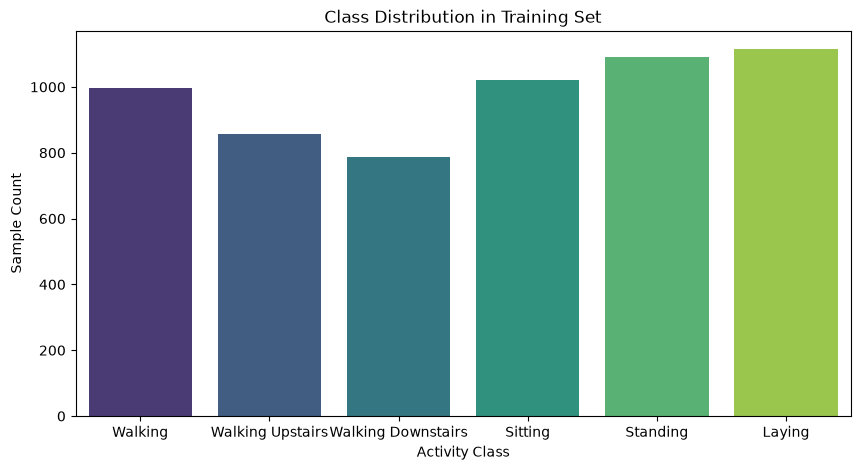

Walking: 997 samples (16.99%)
Walking Upstairs: 857 samples (14.61%)
Walking Downstairs: 786 samples (13.40%)
Sitting: 1022 samples (17.42%)
Standing: 1091 samples (18.60%)
Laying: 1114 samples (18.99%)


In [4]:
# Class Balance Visualization
classes = ['Walking', 'Walking Upstairs', 'Walking Downstairs', 'Sitting', 'Standing', 'Laying']
unique, counts = np.unique(y_train, return_counts=True)
counts_dict = dict(zip(unique, counts))

plt.figure(figsize=(10, 5))
sns.barplot(x=classes, y=[counts_dict[i] for i in range(6)], palette="viridis")
plt.title("Class Distribution in Training Set")
plt.xlabel("Activity Class")
plt.ylabel("Sample Count")
plt.savefig(os.path.join(FIGURE_DIR, "class_balance.png"), dpi=160, bbox_inches="tight")
plt.show()

# Print metrics details
for c_idx, name in enumerate(classes):
    cnt = counts_dict[c_idx]
    pct = cnt / len(y_train) * 100
    print(f"{name}: {cnt} samples ({pct:.2f}%)")


## Custom Cells from Scratch

In [5]:
class MyRNNCell(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.W_ih = nn.Parameter(torch.Tensor(hidden_dim, input_dim))
        self.W_hh = nn.Parameter(torch.Tensor(hidden_dim, hidden_dim))
        self.b_ih = nn.Parameter(torch.Tensor(hidden_dim))
        self.b_hh = nn.Parameter(torch.Tensor(hidden_dim))
        self.reset_parameters()

    def reset_parameters(self):
        std = 1.0 / math.sqrt(self.hidden_dim)
        for p in self.parameters():
            nn.init.uniform_(p, -std, std)

    def forward(self, x: torch.Tensor, h_prev: torch.Tensor) -> torch.Tensor:
        out = F.linear(x, self.W_ih, self.b_ih) + F.linear(h_prev, self.W_hh, self.b_hh)
        return torch.tanh(out)

class MyLSTMCell(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.W_ih = nn.Parameter(torch.Tensor(4 * hidden_dim, input_dim))
        self.W_hh = nn.Parameter(torch.Tensor(4 * hidden_dim, hidden_dim))
        self.b_ih = nn.Parameter(torch.Tensor(4 * hidden_dim))
        self.b_hh = nn.Parameter(torch.Tensor(4 * hidden_dim))
        self.reset_parameters()

    def reset_parameters(self):
        std = 1.0 / math.sqrt(self.hidden_dim)
        for p in self.parameters():
            nn.init.uniform_(p, -std, std)

    def forward(self, x: torch.Tensor, state: tuple) -> tuple:
        h_prev, c_prev = state
        gates = F.linear(x, self.W_ih, self.b_ih) + F.linear(h_prev, self.W_hh, self.b_hh)
        i_t, f_t, g_t, o_t = gates.chunk(4, dim=1)
        i_t = torch.sigmoid(i_t)
        f_t = torch.sigmoid(f_t)
        g_t = torch.tanh(g_t)
        o_t = torch.sigmoid(o_t)
        c_t = f_t * c_prev + i_t * g_t
        h_t = o_t * torch.tanh(c_t)
        return h_t, c_t

class MyGRUCell(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.W_ih = nn.Parameter(torch.Tensor(3 * hidden_dim, input_dim))
        self.W_hh = nn.Parameter(torch.Tensor(3 * hidden_dim, hidden_dim))
        self.b_ih = nn.Parameter(torch.Tensor(3 * hidden_dim))
        self.b_hh = nn.Parameter(torch.Tensor(3 * hidden_dim))
        self.reset_parameters()

    def reset_parameters(self):
        std = 1.0 / math.sqrt(self.hidden_dim)
        for p in self.parameters():
            nn.init.uniform_(p, -std, std)

    def forward(self, x: torch.Tensor, h_prev: torch.Tensor) -> torch.Tensor:
        gates_ih = F.linear(x, self.W_ih, self.b_ih)
        gates_hh = F.linear(h_prev, self.W_hh, self.b_hh)
        r_ih, z_ih, n_ih = gates_ih.chunk(3, dim=1)
        r_hh, z_hh, n_hh = gates_hh.chunk(3, dim=1)
        r = torch.sigmoid(r_ih + r_hh)
        z = torch.sigmoid(z_ih + z_hh)
        n = torch.tanh(n_ih + r * n_hh)
        h_t = (1 - z) * n + z * h_prev
        return h_t

## Problem 1, Task 2: Cell verification and parameter counts

The custom recurrent cells are compared with the corresponding PyTorch cells after copying identical weights and biases. The checks use a maximum absolute tolerance of 1e-5. The selected hidden size is h = 64 for all three cells.

In [6]:
input_dim, hidden_dim = 9, HIDDEN_SIZE
x_test = torch.randn(5, input_dim)
h_test = torch.randn(5, hidden_dim)
c_test = torch.randn(5, hidden_dim)

custom_rnn, torch_rnn = MyRNNCell(input_dim, hidden_dim), nn.RNNCell(input_dim, hidden_dim)
with torch.no_grad():
    custom_rnn.W_ih.copy_(torch_rnn.weight_ih); custom_rnn.W_hh.copy_(torch_rnn.weight_hh)
    custom_rnn.b_ih.copy_(torch_rnn.bias_ih); custom_rnn.b_hh.copy_(torch_rnn.bias_hh)
rnn_error = (custom_rnn(x_test, h_test) - torch_rnn(x_test, h_test)).abs().max().item()
assert rnn_error <= 1e-5, f'RNN mismatch: {rnn_error}'

custom_lstm, torch_lstm = MyLSTMCell(input_dim, hidden_dim), nn.LSTMCell(input_dim, hidden_dim)
with torch.no_grad():
    custom_lstm.W_ih.copy_(torch_lstm.weight_ih); custom_lstm.W_hh.copy_(torch_lstm.weight_hh)
    custom_lstm.b_ih.copy_(torch_lstm.bias_ih); custom_lstm.b_hh.copy_(torch_lstm.bias_hh)
lstm_h, lstm_c = custom_lstm(x_test, (h_test, c_test))
torch_h, torch_c = torch_lstm(x_test, (h_test, c_test))
lstm_error = max((lstm_h - torch_h).abs().max().item(), (lstm_c - torch_c).abs().max().item())
assert lstm_error <= 1e-5, f'LSTM mismatch: {lstm_error}'

custom_gru, torch_gru = MyGRUCell(input_dim, hidden_dim), nn.GRUCell(input_dim, hidden_dim)
with torch.no_grad():
    custom_gru.W_ih.copy_(torch_gru.weight_ih); custom_gru.W_hh.copy_(torch_gru.weight_hh)
    custom_gru.b_ih.copy_(torch_gru.bias_ih); custom_gru.b_hh.copy_(torch_gru.bias_hh)
gru_error = (custom_gru(x_test, h_test) - torch_gru(x_test, h_test)).abs().max().item()
assert gru_error <= 1e-5, f'GRU mismatch: {gru_error}'

for name, error, cell in [('RNN', rnn_error, custom_rnn), ('LSTM', lstm_error, custom_lstm), ('GRU', gru_error, custom_gru)]:
    print(f'{name}: max abs error={error:.3g}, cell parameters={sum(p.numel() for p in cell.parameters()):,}')

RNN: max abs error=0, cell parameters=4,800
LSTM: max abs error=0, cell parameters=19,200
GRU: max abs error=2.38e-07, cell parameters=14,400


## Problem 1, Task 3: HAR classification

Train the RNN, LSTM, and GRU on the subject-wise HAR split for seeds 1, 2, and 3. Each run is logged to the project-level `results.csv`; rerunning a seed replaces its previous row. The best validation run is used for the confusion-matrix figure.

RNN seed=1: test_acc=0.6647, macro_f1=0.6533, params=5,190, sec/epoch=1.81
RNN seed=2: test_acc=0.6105, macro_f1=0.5530, params=5,190, sec/epoch=2.05
RNN seed=3: test_acc=0.5884, macro_f1=0.5643, params=5,190, sec/epoch=1.81
LSTM seed=1: test_acc=0.7530, macro_f1=0.7377, params=19,590, sec/epoch=4.56
LSTM seed=2: test_acc=0.7231, macro_f1=0.6745, params=19,590, sec/epoch=9.27
LSTM seed=3: test_acc=0.7289, macro_f1=0.7162, params=19,590, sec/epoch=8.05
GRU seed=1: test_acc=0.8558, macro_f1=0.8551, params=14,790, sec/epoch=6.50
GRU seed=2: test_acc=0.8208, macro_f1=0.8189, params=14,790, sec/epoch=6.67
GRU seed=3: test_acc=0.8269, macro_f1=0.8234, params=14,790, sec/epoch=7.01


,model_type,seed,val_acc,test_acc,test_f1,params,sec_per_epoch
0,RNN,1,0.694949,0.664744,0.653295,5190,1.812412
1,RNN,2,0.661279,0.610451,0.553003,5190,2.050149
2,RNN,3,0.674074,0.588395,0.564350,5190,1.807902
3,LSTM,1,0.809428,0.752969,0.737725,19590,4.562032
4,LSTM,2,0.774411,0.723108,0.674493,19590,9.270391
5,LSTM,3,0.748148,0.728877,0.716171,19590,8.051165
6,GRU,1,0.895623,0.855786,0.855148,14790,6.501993
7,GRU,2,0.894276,0.820835,0.818934,14790,6.674717
8,GRU,3,0.903030,0.826943,0.823414,14790,7.009608


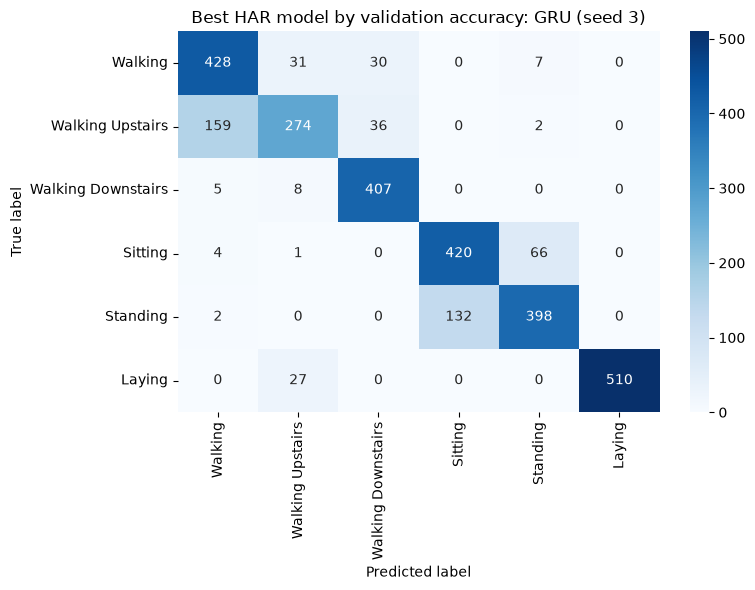

In [7]:
class CustomRNNModel(nn.Module):
    def __init__(self, cell_type, input_dim, hidden_dim, num_classes):
        super().__init__()
        self.cell_type, self.hidden_dim = cell_type, hidden_dim
        cell = {'RNN': MyRNNCell, 'LSTM': MyLSTMCell, 'GRU': MyGRUCell}[cell_type]
        self.cell = cell(input_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        h = x.new_zeros((x.size(0), self.hidden_dim))
        if self.cell_type == 'LSTM':
            c = torch.zeros_like(h)
            for t in range(x.size(1)):
                h, c = self.cell(x[:, t, :], (h, c))
        else:
            for t in range(x.size(1)):
                h = self.cell(x[:, t, :], h)
        return self.fc(h)

class HARSequenceDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.as_tensor(x, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, index): return self.x[index], self.y[index]

train_loader = DataLoader(HARSequenceDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(HARSequenceDataset(X_val, y_val), batch_size=128, shuffle=False)
test_loader = DataLoader(HARSequenceDataset(X_test, y_test), batch_size=128, shuffle=False)

def evaluate_classifier(model, loader):
    model.eval(); predictions, targets = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(device))
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
            targets.extend(yb.numpy())
    accuracy = accuracy_score(targets, predictions)
    _, _, macro_f1, _ = precision_recall_fscore_support(targets, predictions, average='macro', zero_division=0)
    return accuracy, macro_f1, np.asarray(predictions), np.asarray(targets)

def train_har_model(model_type, seed, epochs=5):
    seed_everything(seed)
    model = CustomRNNModel(model_type, 9, HIDDEN_SIZE, 6).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    best_val_loss, best_state = float('inf'), None
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
        model.eval(); val_loss_sum = 0.0; val_count = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                batch_loss = criterion(model(xb), yb)
                val_loss_sum += batch_loss.item() * len(yb); val_count += len(yb)
        if val_loss_sum / val_count < best_val_loss:
            best_val_loss = val_loss_sum / val_count
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    seconds_per_epoch = (time.perf_counter() - start) / epochs
    model.load_state_dict(best_state)
    val_acc, val_f1, _, _ = evaluate_classifier(model, val_loader)
    test_acc, test_f1, preds, targets = evaluate_classifier(model, test_loader)
    params = sum(parameter.numel() for parameter in model.parameters())
    save_result({'problem':'problem1','model':model_type,'seed':seed,'seq_len':128,
        'test_acc':test_acc,'macro_f1':test_f1,'test_mse':np.nan,'params':params,
        'sec_per_epoch':seconds_per_epoch,'val_loss_nats':np.nan,'bits_per_char':np.nan,
        'notes':f'validation_acc={val_acc:.6f}; validation_macro_f1={val_f1:.6f}'})
    return {'model':model,'model_type':model_type,'seed':seed,'val_acc':val_acc,
        'test_acc':test_acc,'test_f1':test_f1,'predictions':preds,'targets':targets,
        'params':params,'sec_per_epoch':seconds_per_epoch}

har_runs = []
for model_type in ('RNN', 'LSTM', 'GRU'):
    for seed in HAR_SEEDS:
        run = train_har_model(model_type, seed)
        har_runs.append(run)
        print(f"{model_type} seed={seed}: test_acc={run['test_acc']:.4f}, macro_f1={run['test_f1']:.4f}, params={run['params']:,}, sec/epoch={run['sec_per_epoch']:.2f}")

har_results = pd.DataFrame([{key: run[key] for key in ('model_type','seed','val_acc','test_acc','test_f1','params','sec_per_epoch')} for run in har_runs])
display(har_results)
best_har = max(har_runs, key=lambda run: run['val_acc'])
confusion = np.zeros((6, 6), dtype=int)
np.add.at(confusion, (best_har['targets'], best_har['predictions']), 1)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted label'); plt.ylabel('True label')
plt.title(f"Best HAR model by validation accuracy: {best_har['model_type']} (seed {best_har['seed']})")
plt.tight_layout(); plt.savefig(os.path.join(FIGURE_DIR, 'har_best_confusion_matrix.png'), dpi=160); plt.show()

## Problem 1, Task 4: Adding problem

The two marked positions are sampled from opposite sequence halves, so every example has exactly two markers. Targets remain floating-point sums. The cell runs the three recurrent models at T = 50, 100, 200, and 400; the T = 200 training curves and test MSE versus T are saved as figures.

RNN T=50: test_mse=0.16167, solved=False, sec/epoch=0.38
LSTM T=50: test_mse=0.19750, solved=False, sec/epoch=0.85
GRU T=50: test_mse=0.16100, solved=False, sec/epoch=0.77
RNN T=100: test_mse=0.18366, solved=False, sec/epoch=0.68
LSTM T=100: test_mse=0.22858, solved=False, sec/epoch=1.68
GRU T=100: test_mse=0.18432, solved=False, sec/epoch=1.07
RNN T=200: test_mse=0.15173, solved=False, sec/epoch=1.42
LSTM T=200: test_mse=0.21294, solved=False, sec/epoch=3.45
GRU T=200: test_mse=0.15311, solved=False, sec/epoch=3.07
RNN T=400: test_mse=0.17137, solved=False, sec/epoch=2.44
LSTM T=400: test_mse=0.23916, solved=False, sec/epoch=9.38
GRU T=400: test_mse=0.17224, solved=False, sec/epoch=7.86


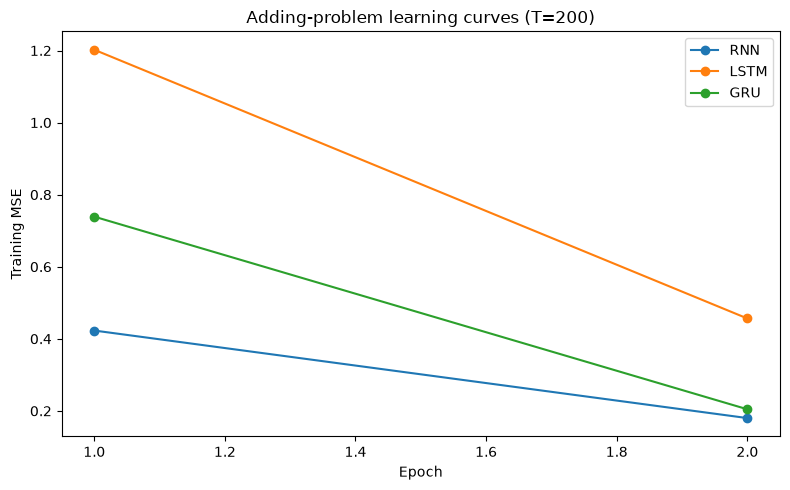

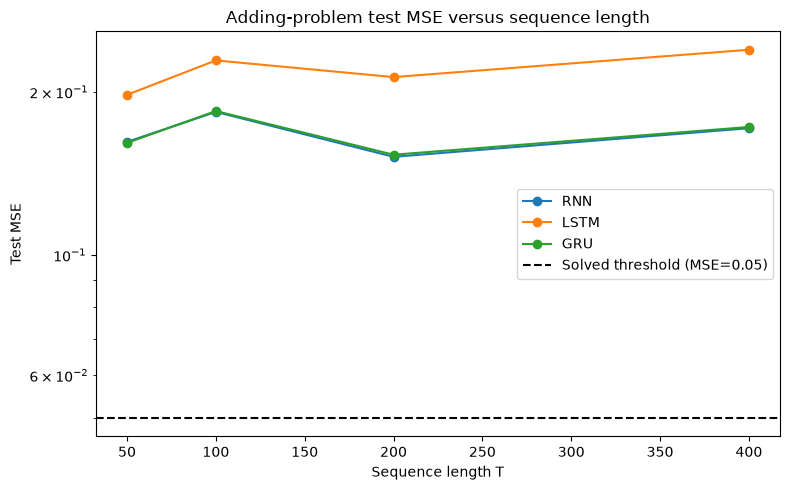

In [8]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    rows = np.arange(n)
    x[rows, i1, 1] = 1.0; x[rows, i2, 1] = 1.0
    y = x[rows, i1, 0] + x[rows, i2, 0]
    return x, y.astype(np.float32)

class AddingModel(nn.Module):
    def __init__(self, cell_type, hidden_dim):
        super().__init__(); self.cell_type, self.hidden_dim = cell_type, hidden_dim
        cell = {'RNN': MyRNNCell, 'LSTM': MyLSTMCell, 'GRU': MyGRUCell}[cell_type]
        self.cell = cell(2, hidden_dim); self.fc = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        h = x.new_zeros((x.size(0), self.hidden_dim))
        if self.cell_type == 'LSTM':
            c = torch.zeros_like(h)
            for t in range(x.size(1)): h, c = self.cell(x[:, t, :], (h, c))
        else:
            for t in range(x.size(1)): h = self.cell(x[:, t, :], h)
        return self.fc(h).squeeze(-1)

def tensor_loader(x, y, batch_size=128, shuffle=False):
    dataset = torch.utils.data.TensorDataset(torch.from_numpy(x), torch.from_numpy(y))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

def train_adding(model_type, T, seed=42, hidden_dim=HIDDEN_SIZE, epochs=2, n_train=2048, n_eval=512):
    seed_everything(seed)
    x_train, y_train = make_adding(n_train, T, seed=seed + 100)
    x_val, y_val = make_adding(n_eval, T, seed=seed + 200)
    x_test, y_test = make_adding(n_eval, T, seed=seed + 300)
    train_batches = tensor_loader(x_train, y_train, shuffle=True)
    val_batches = tensor_loader(x_val, y_val)
    test_batches = tensor_loader(x_test, y_test)
    model = AddingModel(model_type, hidden_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3); criterion = nn.MSELoss()
    epoch_losses, start = [], time.perf_counter()
    for _ in range(epochs):
        model.train(); total_loss = 0.0; count = 0
        for xb, yb in train_batches:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(yb); count += len(yb)
        epoch_losses.append(total_loss / count)
    seconds_per_epoch = (time.perf_counter() - start) / epochs
    model.eval(); test_preds, test_targets = [], []
    with torch.no_grad():
        for xb, yb in test_batches:
            test_preds.extend(model(xb.to(device)).cpu().numpy()); test_targets.extend(yb.numpy())
    test_mse = float(np.mean((np.asarray(test_preds) - np.asarray(test_targets)) ** 2))
    params = sum(parameter.numel() for parameter in model.parameters())
    model_name = f'{model_type}_adding' if hidden_dim == HIDDEN_SIZE else f'{model_type}_h{hidden_dim}_adding'
    save_result({'problem':'problem1','model':model_name,'seed':seed,'seq_len':T,
        'test_acc':np.nan,'macro_f1':np.nan,'test_mse':test_mse,'params':params,
        'sec_per_epoch':seconds_per_epoch,'val_loss_nats':np.nan,'bits_per_char':np.nan,
        'notes':f'epochs={epochs}; hidden_size={hidden_dim}; solved={test_mse < 0.05}'})
    return {'mse':test_mse,'params':params,'losses':epoch_losses,'seconds_per_epoch':seconds_per_epoch}

ADDING_EPOCHS = 2
ADDING_LENGTHS = [50, 100, 200, 400]
ADDING_SEED = 42
adding_results, adding_curves = {}, {}
for T in ADDING_LENGTHS:
    for model_type in ('RNN', 'LSTM', 'GRU'):
        run = train_adding(model_type, T, seed=ADDING_SEED, epochs=ADDING_EPOCHS)
        adding_results[(model_type, T)] = run['mse']
        if T == 200: adding_curves[model_type] = run['losses']
        print(f"{model_type} T={T}: test_mse={run['mse']:.5f}, solved={run['mse'] < 0.05}, sec/epoch={run['seconds_per_epoch']:.2f}")

plt.figure(figsize=(8, 5))
for model_type, losses in adding_curves.items(): plt.plot(range(1, len(losses)+1), losses, marker='o', label=model_type)
plt.xlabel('Epoch'); plt.ylabel('Training MSE'); plt.title('Adding-problem learning curves (T=200)'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'adding_learning_curves_T200.png'), dpi=160); plt.show()
plt.figure(figsize=(8, 5))
for model_type in ('RNN', 'LSTM', 'GRU'):
    plt.plot(ADDING_LENGTHS, [adding_results[(model_type, T)] for T in ADDING_LENGTHS], marker='o', label=model_type)
plt.axhline(0.05, color='black', linestyle='--', label='Solved threshold (MSE=0.05)')
plt.xlabel('Sequence length T'); plt.ylabel('Test MSE'); plt.yscale('log'); plt.title('Adding-problem test MSE versus sequence length'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'adding_mse_by_T.png'), dpi=160); plt.show()

## Problem 1, Task 5(a): Gradient flow over time

For each recurrent model, compute the gradient norm of the loss with respect to each hidden state on the same generated sequence. The log-scale plot is saved under `problem1/figures/`.

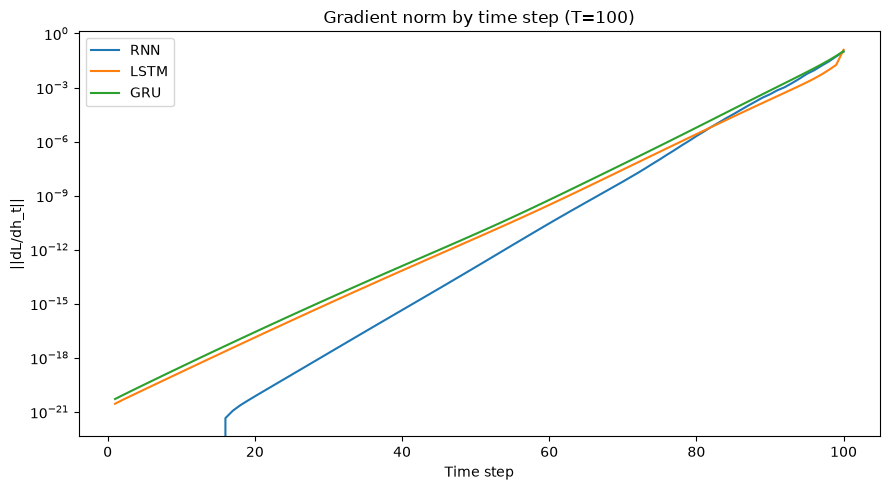

In [9]:
def hidden_state_gradient_norms(model_type, T=100, seed=42):
    seed_everything(seed); batch_size = 128
    model = AddingModel(model_type, HIDDEN_SIZE).to(device)
    x, y = make_adding(batch_size, T, seed=seed + 1)
    x_t, y_t = torch.from_numpy(x).to(device), torch.from_numpy(y).to(device)
    h = torch.zeros(batch_size, HIDDEN_SIZE, device=device); states = []
    if model_type == 'LSTM':
        c = torch.zeros_like(h)
        for t in range(T):
            h, c = model.cell(x_t[:, t, :], (h, c)); h.retain_grad(); states.append(h)
    else:
        for t in range(T):
            h = model.cell(x_t[:, t, :], h); h.retain_grad(); states.append(h)
    loss = nn.MSELoss()(model.fc(h).squeeze(-1), y_t); loss.backward()
    return [state.grad.norm().item() for state in states]

plt.figure(figsize=(9, 5))
for model_type in ('RNN', 'LSTM', 'GRU'):
    plt.plot(range(1, 101), hidden_state_gradient_norms(model_type), label=model_type)
plt.yscale('log'); plt.xlabel('Time step'); plt.ylabel('||dL/dh_t||')
plt.title('Gradient norm by time step (T=100)'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'gradient_norms.png'), dpi=160); plt.show()

## Problem 1, Task 5(b): Hidden-size sweep

Sweep the vanilla RNN hidden size on the T=200 adding task, then plot test MSE against parameter count. Each run is separately named and logged so it does not overwrite the standard h=64 run.

,hidden_size,params,test_mse
0,16,337,0.489483
1,32,1185,0.167455
2,64,4417,0.151734
3,128,17025,0.151665


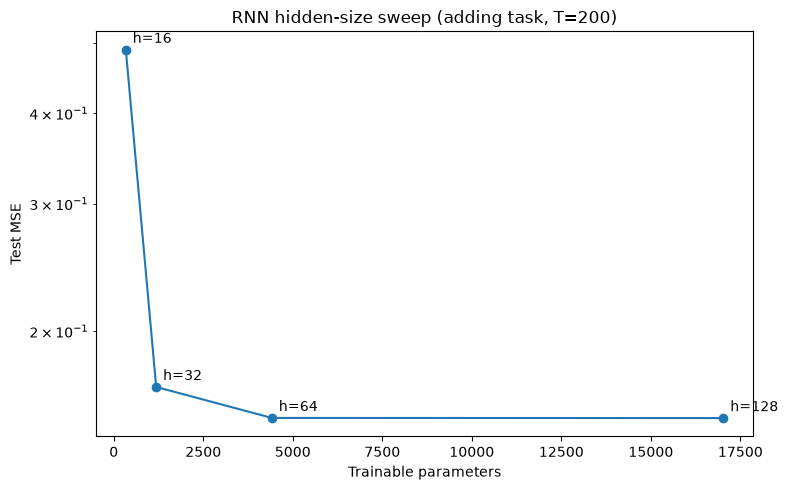

In [10]:
SWEEP_HIDDEN_SIZES = [16, 32, 64, 128]
hidden_sweep = []
for hidden_size in SWEEP_HIDDEN_SIZES:
    run = train_adding('RNN', 200, seed=ADDING_SEED, hidden_dim=hidden_size, epochs=ADDING_EPOCHS)
    hidden_sweep.append({'hidden_size':hidden_size,'params':run['params'],'test_mse':run['mse']})
hidden_sweep_df = pd.DataFrame(hidden_sweep)
display(hidden_sweep_df)
plt.figure(figsize=(8, 5)); plt.plot(hidden_sweep_df['params'], hidden_sweep_df['test_mse'], marker='o')
for _, row in hidden_sweep_df.iterrows(): plt.annotate(f"h={int(row['hidden_size'])}", (row['params'], row['test_mse']), xytext=(5, 5), textcoords='offset points')
plt.xlabel('Trainable parameters'); plt.ylabel('Test MSE'); plt.yscale('log')
plt.title('RNN hidden-size sweep (adding task, T=200)'); plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'hidden_size_sweep.png'), dpi=160); plt.show()

## Problem 1, Task 5(c): Gradient-clipping ablation

Compare the same vanilla RNN setup with no clipping and with global gradient norm clipping at 1.0. Training losses and final test MSE are plotted/reported.

No clipping: final test MSE=0.15173
Clip norm 1.0: final test MSE=0.15999


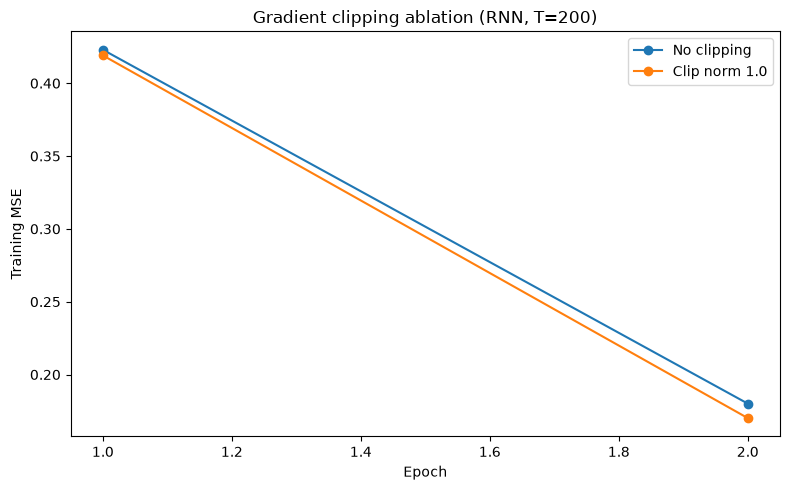

In [11]:
def train_clipping_ablation(clip_value, T=200, epochs=2, seed=42):
    seed_everything(seed)
    x_train, y_train = make_adding(2048, T, seed=seed + 100)
    x_test, y_test = make_adding(512, T, seed=seed + 300)
    train_batches = tensor_loader(x_train, y_train, shuffle=True)
    test_batches = tensor_loader(x_test, y_test)
    model = AddingModel('RNN', HIDDEN_SIZE).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3); criterion = nn.MSELoss()
    losses = []
    for _ in range(epochs):
        model.train(); total_loss = 0.0; count = 0
        for xb, yb in train_batches:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward()
            if clip_value is not None: torch.nn.utils.clip_grad_norm_(model.parameters(), clip_value)
            optimizer.step(); total_loss += loss.item() * len(yb); count += len(yb)
        losses.append(total_loss / count)
    model.eval(); predictions, targets = [], []
    with torch.no_grad():
        for xb, yb in test_batches:
            predictions.extend(model(xb.to(device)).cpu().numpy()); targets.extend(yb.numpy())
    mse = float(np.mean((np.asarray(predictions) - np.asarray(targets)) ** 2))
    return losses, mse

clip_results = {}
for label, clip_value in [('No clipping', None), ('Clip norm 1.0', 1.0)]:
    losses, mse = train_clipping_ablation(clip_value)
    clip_results[label] = {'losses':losses,'test_mse':mse}
    print(f'{label}: final test MSE={mse:.5f}')
plt.figure(figsize=(8, 5))
for label, result in clip_results.items(): plt.plot(range(1, len(result['losses'])+1), result['losses'], marker='o', label=label)
plt.xlabel('Epoch'); plt.ylabel('Training MSE'); plt.title('Gradient clipping ablation (RNN, T=200)'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'clipping_ablation.png'), dpi=160); plt.show()